# Figuras para la sección 2: Exploración y análisis de los datos

Este notebook genera dos figuras compactas para el informe:

1. **Distribución de clases** (`background` vs `signal`) para la subsección 2.1.
2. **Cantidad de jets y faltantes estructurales** para conectar las subsecciones 2.2 y 2.3.

Las imágenes se guardan en `img/` para ser incorporadas directamente en LaTeX.

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


SPECIAL_COLUMNS = ["EventId", "Weight", "Label", "KaggleSet", "KaggleWeight"]
MISSING_MARKER = -999.0


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raiz del proyecto.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "higgs-boson" / "training.csv"
IMG_DIR = PROJECT_ROOT / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "figure.dpi": 140,
        "savefig.dpi": 260,
        "font.size": 11,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

train_df = pd.read_csv(DATA_PATH)
feature_cols = [column for column in train_df.columns if column not in SPECIAL_COLUMNS]
X = train_df[feature_cols].replace(MISSING_MARKER, np.nan)

print(f"Datos cargados desde: {DATA_PATH}")
print(f"Filas training: {len(train_df):,}")
print(f"Features: {len(feature_cols)}")

Datos cargados desde: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/training.csv
Filas training: 250,000
Features: 30


## Figura 1: distribución de clases

Esta figura resume la variable objetivo del problema. La clase `b` representa `background` y la clase `s` representa `signal`.

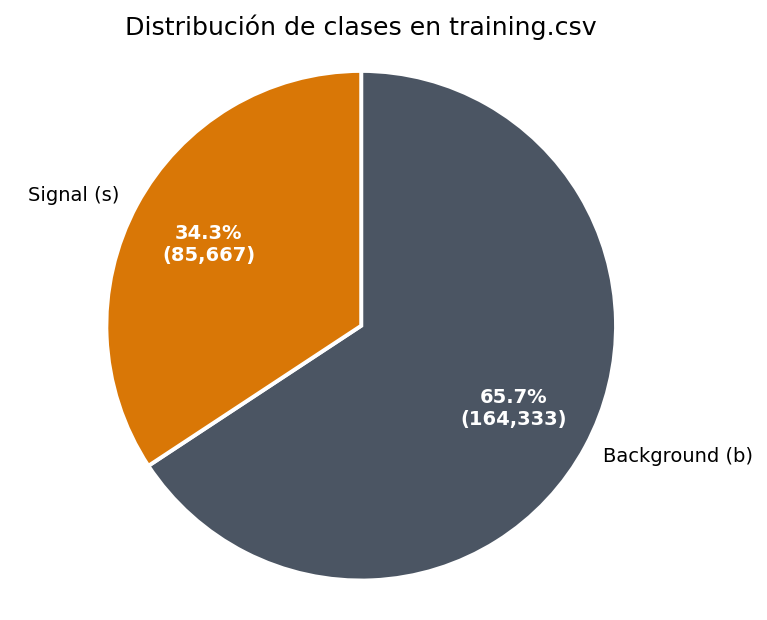

Figura guardada en: /home/santig14/fing/taa/1_TallerAA/img/fig_2_1_distribucion_clases.png


In [2]:
class_counts = train_df["Label"].value_counts().reindex(["b", "s"])
class_percentages = class_counts / class_counts.sum() * 100

labels = ["Background (b)", "Signal (s)"]
colors = ["#4B5563", "#D97706"]

def class_autopct(percent: float) -> str:
    count = int(round(percent / 100 * class_counts.sum()))
    return f"{percent:.1f}%\n({count:,})"


fig, ax = plt.subplots(figsize=(6.4, 5.2))
wedges, _, autotexts = ax.pie(
    class_counts.values,
    labels=labels,
    colors=colors,
    startangle=90,
    counterclock=False,
    autopct=class_autopct,
    pctdistance=0.68,
    labeldistance=1.08,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)

for text in autotexts:
    text.set_color("white")
    text.set_fontweight("bold")
    text.set_fontsize(10)

ax.set_title("Distribución de clases en training.csv")
ax.axis("equal")

figure_path = IMG_DIR / "fig_2_1_distribucion_clases.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: {figure_path}")

## Figura 2: cantidad de jets y faltantes estructurales

Esta figura combina dos aspectos centrales del análisis: la distribución de `PRI_jet_num` y el porcentaje de valores faltantes de variables importantes para cada cantidad de jets. Los `-999` se reemplazan por `NaN` antes del cálculo.

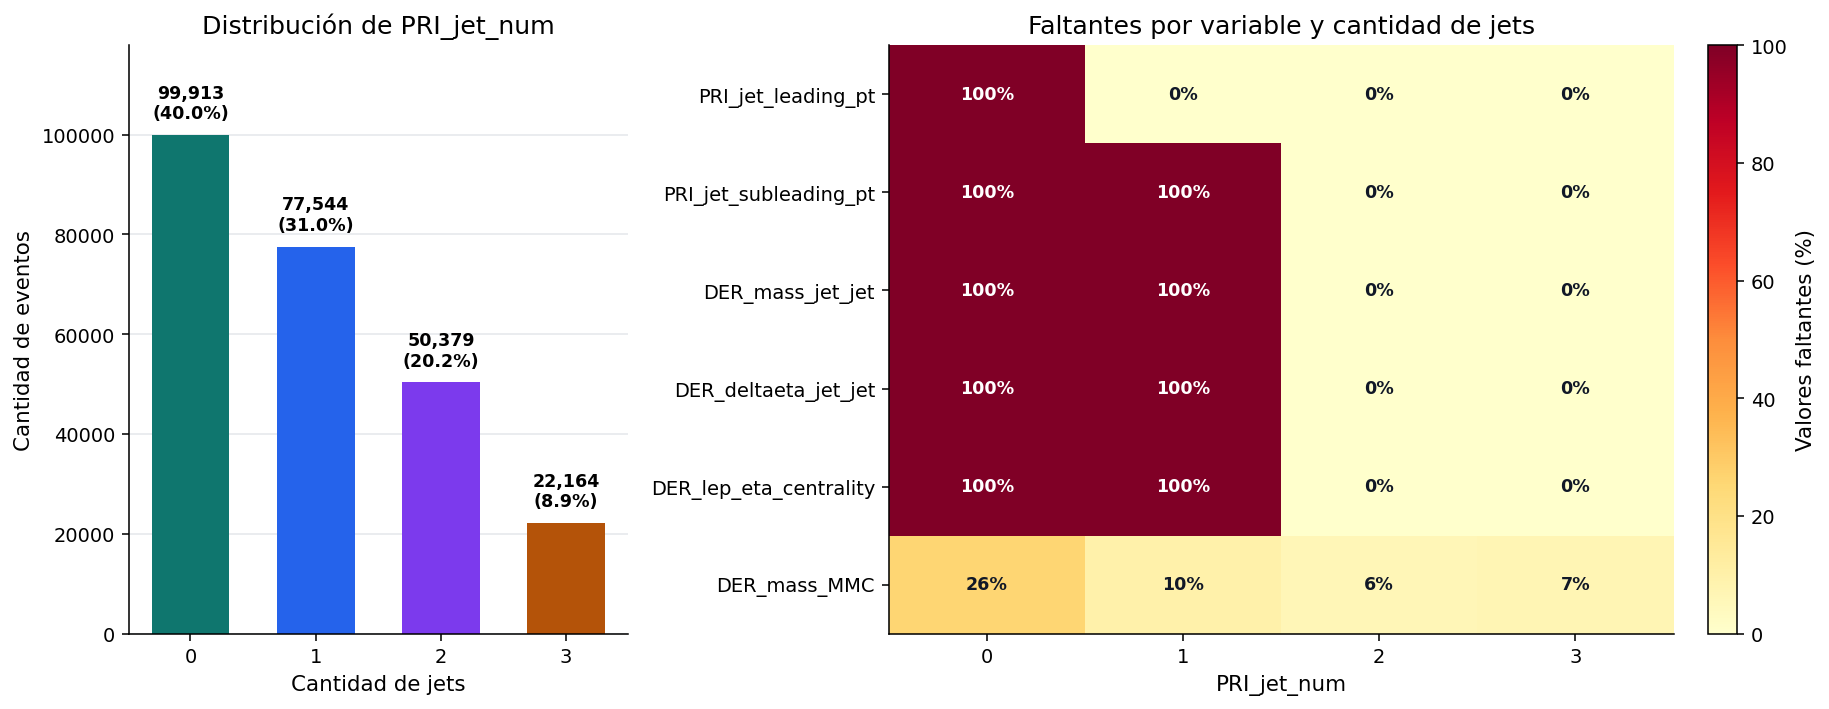

Figura guardada en: /home/santig14/fing/taa/1_TallerAA/img/fig_2_2_missing_y_jets.png


In [3]:
jet_counts = X["PRI_jet_num"].astype(int).value_counts().sort_index().reindex([0, 1, 2, 3])
jet_percentages = jet_counts / jet_counts.sum() * 100

missing_columns = [
    "PRI_jet_leading_pt",
    "PRI_jet_subleading_pt",
    "DER_mass_jet_jet",
    "DER_deltaeta_jet_jet",
    "DER_lep_eta_centrality",
    "DER_mass_MMC",
]

missing_by_jet = (
    X.groupby(X["PRI_jet_num"].astype(int))[missing_columns]
    .apply(lambda group: group.isna().mean() * 100)
    .reindex([0, 1, 2, 3])
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13.2, 5.2),
    gridspec_kw={"width_ratios": [0.9, 1.55]},
)

jet_colors = ["#0F766E", "#2563EB", "#7C3AED", "#B45309"]
bars = axes[0].bar(jet_counts.index.astype(str), jet_counts.values, color=jet_colors, width=0.62)
for bar, count, pct in zip(bars, jet_counts.values, jet_percentages.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + jet_counts.max() * 0.025,
        f"{count:,}\n({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold",
    )

axes[0].set_title("Distribución de PRI_jet_num")
axes[0].set_xlabel("Cantidad de jets")
axes[0].set_ylabel("Cantidad de eventos")
axes[0].set_ylim(0, jet_counts.max() * 1.18)
axes[0].grid(axis="y", color="#E5E7EB", linewidth=0.8)
axes[0].set_axisbelow(True)

heatmap_values = missing_by_jet.T.values
image = axes[1].imshow(heatmap_values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=100)
axes[1].set_title("Faltantes por variable y cantidad de jets")
axes[1].set_xlabel("PRI_jet_num")
axes[1].set_xticks(np.arange(len(missing_by_jet.index)))
axes[1].set_xticklabels(missing_by_jet.index.astype(str))
axes[1].set_yticks(np.arange(len(missing_columns)))
axes[1].set_yticklabels(missing_columns)

for row_idx in range(heatmap_values.shape[0]):
    for col_idx in range(heatmap_values.shape[1]):
        value = heatmap_values[row_idx, col_idx]
        text_color = "white" if value >= 55 else "#111827"
        axes[1].text(
            col_idx,
            row_idx,
            f"{value:.0f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=9,
            fontweight="bold",
        )

colorbar = fig.colorbar(image, ax=axes[1], fraction=0.046, pad=0.04)
colorbar.set_label("Valores faltantes (%)")

fig.tight_layout()
figure_path = IMG_DIR / "fig_2_2_missing_y_jets.png"
fig.savefig(figure_path, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: {figure_path}")